# Deteksi Malicious URL Menggunakan Random Forest Classifier
## Bagian 1: Akuisisi Data, Exploratory Data Analysis (EDA) & Ekstraksi Fitur (Tahap 1 - 3)

**Mata Kuliah**: Keamanan Berbasis Sistem Cerdas (UTS Semester 7)  
**Program Studi**: Teknik Informatika - Universitas Darma Persada (UNSADA)  
**Penyusun**: Sayyid Abdullah Azzam  

---

### Alur Kerja Bagian 1:
1. **Tahap 1: Akuisisi Data (Kaggle)**  
   - Mengunduh dataset *Malicious URLs dataset* (`malicious_phish.csv`) via `kagglehub` / lokal `dataset/`.
   - Mengambil sampel terukur 20.000 baris untuk efisiensi komputasi demonstrasi video.
2. **Tahap 2: Exploratory Data Analysis (EDA)**  
   - Analisis kelengkapan data & struktur kolom.
   - Visualisasi distribusi kategori URL (Countplot & Pie Chart).
   - Identifikasi permasalahan ketidakseimbangan kelas (*Imbalanced Data: Benign >> Malicious*).
3. **Tahap 3: Data Preprocessing & Feature Engineering**  
   - Pembersihan data: Hapus nilai *missing values* (`dropna`) dan duplikat.
   - Binerisasi label: `Benign -> 0 (Aman)`, `Phishing/Malware/Defacement -> 1 (Bahaya)`.
   - *Lexical Feature Extraction*: Mengubah teks URL menjadi 8 fitur numerik ancaman siber.
   - Menyimpan dataset fitur yang telah diproses ke `dataset/extracted_features.csv` untuk digunakan pada Bagian 2.

In [1]:
# ==============================================================================
# INSTALASI DEPENDENSI (Jika dijalankan di Google Colab atau lingkungan baru)
# ==============================================================================
# Hapus tanda '#' di bawah jika paket belum terpasang di sistem Anda:
# !pip install kagglehub[pandas-datasets] imbalanced-learn scikit-learn seaborn matplotlib pandas numpy

---
## Tahap 1: Akuisisi Data (Kaggle & Lokal)

Dataset yang digunakan adalah **Malicious URLs Dataset** (`malicious_phish.csv`) karya Sidharth Sharma (`sid321axn/malicious-urls-dataset`) dari Kaggle.
Dataset ini memuat ratusan ribu URL dengan dua kolom utama:
- `url`: Teks link tautan web.
- `type`: Kategori ancaman (`benign`, `phishing`, `malware`, `defacement`).

Sistem akan memuat dataset secara otomatis melalui pustaka resmi `kagglehub` atau dari penyimpanan lokal di folder `dataset/malicious_phish.csv`.

In [1]:
import os
import re
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Kagglehub untuk akuisisi dataset resmi
import kagglehub
from kagglehub import KaggleDatasetAdapter

warnings.filterwarnings('ignore')

# Konfigurasi visualisasi
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 120

print("Modul analisis data berhasil diimpor!")

Modul analisis data berhasil diimpor!


c:\Users\W4GONE\AppData\Local\Programs\Python\Python314\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# Nama file dataset target
file_path = "malicious_phish.csv"
local_dataset_path = os.path.join("dataset", file_path)

# Cek ketersediaan file dataset di direktori lokal 'dataset/'
if os.path.exists(local_dataset_path):
    print(f"Memuat dataset langsung dari penyimpanan lokal: {local_dataset_path}")
    df_raw = pd.read_csv(local_dataset_path)
else:
    print("Mengunduh dataset dari Kaggle via kagglehub...")
    df_raw = kagglehub.load_dataset(
        KaggleDatasetAdapter.PANDAS,
        "sid321axn/malicious-urls-dataset",
        file_path,
    )
    # Simpan ke folder dataset lokal untuk penggunaan offline
    os.makedirs("dataset", exist_ok=True)
    df_raw.to_csv(local_dataset_path, index=False)
    print(f"Dataset berhasil disimpan ke: {local_dataset_path}")

print(f"Dataset berhasil dimuat!")
print(f"Dimensi total dataset asli: {df_raw.shape[0]:,} baris dan {df_raw.shape[1]} kolom.")
print("\nFirst 5 records:")
display(df_raw.head())

Memuat dataset langsung dari penyimpanan lokal: dataset\malicious_phish.csv
Dataset berhasil dimuat!
Dimensi total dataset asli: 651,191 baris dan 2 kolom.

First 5 records:


,url,type
0,br-icloud.com.br,phishing
1,mp3raid.com/music/krizz_kaliko.html,benign
2,bopsecrets.org/rexroth/cr/1.htm,benign
3,http://www.garage-pirenne.be/index.php?option=...,defacement
4,http://adventure-nicaragua.net/index.php?optio...,defacement


In [3]:
# ==============================================================================
# PENGAMBILAN SAMPEL TERUKUR (20.000 BARIS)
# ==============================================================================
# Pengambilan sampel dilakukan agar komputasi saat demo video berjalan cepat dalam hitungan detik.
SAMPLE_SIZE = 20000

df = df_raw.sample(n=SAMPLE_SIZE, random_state=42).reset_index(drop=True).copy()

print(f"Sampel terukur berhasil diambil: {df.shape[0]:,} baris.")
print("5 data sampel awal:")
display(df.head())

Sampel terukur berhasil diambil: 20,000 baris.
5 data sampel awal:


,url,type
0,http://37.49.226.178/deusbins/deus.sh4,malware
1,medical-dictionary.thefreedictionary.com/Galt+...,benign
2,www.jscape.com/sshfactory/,phishing
3,http://www.wsnc.org.au/component/jcalpro/view/983,defacement
4,virtualtourist.com/travel/North_America/Canada...,benign


---
## Tahap 2: Exploratory Data Analysis (EDA)

Pada tahap ini dilakukan:
1. Pengecekan struktur kolom dan keberadaan nilai kosong (*missing values*).
2. Pengecekan distribusi kategori URL asli (`benign`, `defacement`, `phishing`, `malware`).
3. Visualisasi *countplot* dan *pie chart* untuk membuktikan permasalahan **Class Imbalance** (kategori *benign* jauh lebih banyak dibandingkan kategori berbahaya).

In [4]:
# 1. Pengecekan struktur dataset & nilai null
print("--- Informasi Struktur Data ---")
df.info()

print("\n--- Jumlah Missing Values Per Kolom ---")
print(df.isnull().sum())

print("\n--- Distribusi Kategori Kelas Asli ---")
class_counts = df['type'].value_counts()
print(class_counts)

--- Informasi Struktur Data ---
<class 'pandas.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   url     20000 non-null  str  
 1   type    20000 non-null  str  
dtypes: str(2)
memory usage: 312.6 KB

--- Jumlah Missing Values Per Kolom ---
url     0
type    0
dtype: int64

--- Distribusi Kategori Kelas Asli ---
type
benign        13216
defacement     2891
phishing       2857
malware        1036
Name: count, dtype: int64


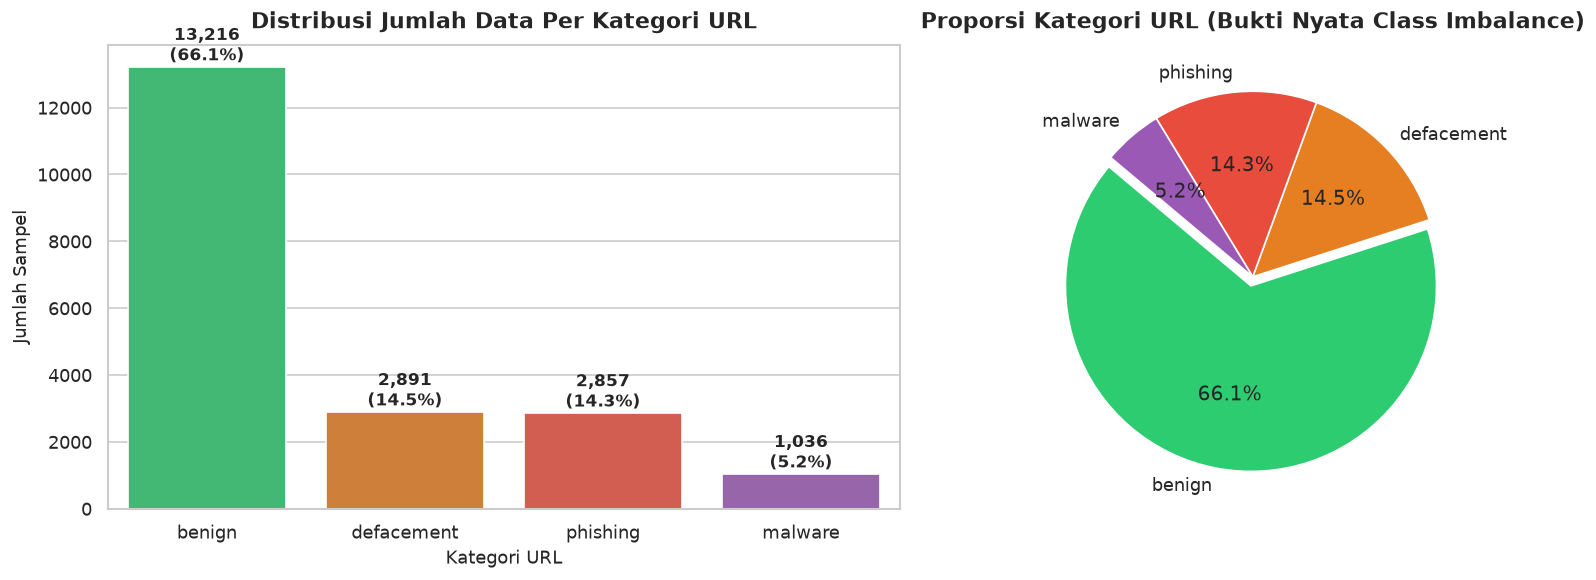

In [5]:
# 2. Visualisasi Distribusi Kategori URL Asli (Bar Chart & Pie Chart)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Subplot 1: Barplot Frekuensi Kelas
palette_colors = ['#2ecc71', '#e67e22', '#e74c3c', '#9b59b6']
sns.barplot(x=class_counts.index, y=class_counts.values, palette=palette_colors, ax=axes[0])
axes[0].set_title("Distribusi Jumlah Data Per Kategori URL", fontsize=13, fontweight='bold', pad=10)
axes[0].set_xlabel("Kategori URL", fontsize=11)
axes[0].set_ylabel("Jumlah Sampel", fontsize=11)

for idx, val in enumerate(class_counts.values):
    pct = (val / len(df)) * 100
    axes[0].text(idx, val + 200, f"{val:,}\n({pct:.1f}%)", ha='center', fontsize=10, fontweight='bold')

# Subplot 2: Donut / Pie Chart Proporsi
axes[1].pie(
    class_counts.values, 
    labels=class_counts.index, 
    autopct='%1.1f%%',
    colors=palette_colors,
    startangle=140, 
    explode=[0.05, 0, 0, 0]
)
axes[1].set_title("Proporsi Kategori URL (Bukti Nyata Class Imbalance)", fontsize=13, fontweight='bold', pad=10)

plt.tight_layout()
plt.show()

---
## Tahap 3: Data Preprocessing & Feature Engineering

### 1. Data Cleaning
- Menghapus nilai kosong (*missing values*) menggunakan `dropna()`.
- Menghapus data duplikat pada kolom `url` agar model tidak mempelajari URL yang sama berulang kali.

### 2. Binary Labeling
- **`0`**: **Aman (Benign)**
- **`1`**: **Bahaya (Malicious)** — penggabungan kelas `phishing`, `defacement`, dan `malware`.

### 3. Lexical Feature Extraction (8 Fitur Angka)
Ekstraksi struktur URL menjadi 8 fitur leksikal numerik:
| No | Nama Fitur | Deskripsi | Signifikansi Keamanan Siber |
|:---|:---|:---|:---|
| 1 | `panjang_url` (`url_length`) | Panjang karakter URL | URL phishing sering dipanjangkan untuk mengaburkan nama domain asli. |
| 2 | `jml_titik` (`count_dot`) | Jumlah tanda titik (`.`) | Subdomain bertingkat (*multi-level subdomains*) untuk meniru portal resmi. |
| 3 | `jml_strip` (`count_hyphen`) | Jumlah tanda hubung (`-`) | Sering digunakan dalam teknik *typosquatting* penipuan brand. |
| 4 | `jml_slash` (`count_slash`) | Jumlah garis miring (`/`) | Menunjukkan kedalaman direktori path tempat skrip berbahaya bersarang. |
| 5 | `simbol_at` (`count_at`) | Jumlah simbol `@` | Simbol `@` membuat browser mengabaikan teks sebelumnya sebagai user credential. |
| 6 | `jml_angka` (`count_digits`) | Jumlah karakter angka/digit | Deretan angka acak atau token session palsu sering dipakai penyerang. |
| 7 | `penggunaan_ip` (`has_ip`) | Deteksi pola IPv4 langsung | URL berbasis alamat IP langsung tanpa nama domain sah adalah indikator kuat penipuan. |
| 8 | `kata_kunci_phish` (`has_phish_keywords`) | Deteksi kata kunci mencurigakan | Kata sensitif perbankan/keamanan: `login`, `verify`, `update`, `banking`, `secure`, `account`, `signin`, `webscr`, `password`, `ebayisapi`, `wallet`, `admin`. |

In [6]:
# 1. Pembersihan duplikat & missing values
initial_rows = len(df)
df = df.dropna().drop_duplicates(subset=['url']).reset_index(drop=True)
print(f"Data setelah pembersihan duplikat: {len(df):,} baris (Dihapus: {initial_rows - len(df)} baris).")

# 2. Binary Labeling (0 = Aman, 1 = Bahaya)
df['label'] = df['type'].apply(lambda x: 0 if x == 'benign' else 1)
df['label_name'] = df['label'].map({0: 'Aman (Benign)', 1: 'Bahaya (Malicious)'})

print("\nDistribusi Label Biner:")
binary_distribution = df['label_name'].value_counts()
print(binary_distribution)

Data setelah pembersihan duplikat: 19,920 baris (Dihapus: 80 baris).

Distribusi Label Biner:
label_name
Aman (Benign)         13216
Bahaya (Malicious)     6704
Name: count, dtype: int64


In [7]:
# 3. Fungsi Ekstraksi 8 Fitur Leksikal URL
def extract_lexical_features(urls_series):
    """
    Mengekstrak 8 fitur numerik berbasis struktur teks (leksikal) URL.
    Input : pandas.Series berupa teks URL
    Output: pandas.DataFrame memuat 8 fitur numerik
    """
    urls = urls_series.astype(str)
    features = pd.DataFrame(index=urls_series.index)
    
    # 1. panjang_url (url_length)
    features['url_length'] = urls.apply(len)
    
    # 2. jml_titik (count_dot)
    features['count_dot'] = urls.apply(lambda x: x.count('.'))
    
    # 3. jml_strip (count_hyphen)
    features['count_hyphen'] = urls.apply(lambda x: x.count('-'))
    
    # 4. jml_slash (count_slash)
    features['count_slash'] = urls.apply(lambda x: x.count('/'))
    
    # 5. simbol_at (count_at)
    features['count_at'] = urls.apply(lambda x: x.count('@'))
    
    # 6. jml_angka (count_digits)
    features['count_digits'] = urls.apply(lambda x: sum(c.isdigit() for c in x))
    
    # 7. penggunaan_ip (has_ip) - Deteksi IPv4
    ipv4_pattern = r'(?:https?://)?(?:\d{1,3}\.){3}\d{1,3}'
    features['has_ip'] = urls.apply(lambda x: 1 if re.search(ipv4_pattern, x) else 0)
    
    # 8. kata_kunci_phish (has_phish_keywords)
    phish_keywords = [
        'login', 'verify', 'update', 'banking', 'secure', 
        'account', 'signin', 'webscr', 'password', 'ebayisapi', 
        'wallet', 'admin'
    ]
    features['has_phish_keywords'] = urls.apply(
        lambda x: 1 if any(kw in x.lower() for kw in phish_keywords) else 0
    )
    
    return features

# Ekstraksi fitur pada dataset
print("Mengekstrak 8 fitur leksikal dari seluruh URL...")
X = extract_lexical_features(df['url'])
y = df['label']

print(f"Ekstraksi selesai! Dimensi matriks fitur X: {X.shape}")
print("\n5 Baris Pertama Fitur yang Diekstrak:")
display(X.head())

Mengekstrak 8 fitur leksikal dari seluruh URL...
Ekstraksi selesai! Dimensi matriks fitur X: (19920, 8)

5 Baris Pertama Fitur yang Diekstrak:


,url_length,count_dot,count_hyphen,count_slash,count_at,count_digits,has_ip,has_phish_keywords
0,38,4,0,4,0,11,1,0
1,54,2,1,1,0,0,0,0
2,26,2,0,2,0,0,0,0
3,49,3,0,6,0,3,0,0
4,121,2,5,6,0,7,0,0


In [8]:
# Analisis Komparasi Nilai Rata-rata Fitur per Kelas
analysis_df = X.copy()
analysis_df['label_name'] = df['label_name']

print("Rata-rata Nilai Fitur Antara URL Aman vs Bahaya:")
mean_comparison = analysis_df.groupby('label_name').mean()
display(mean_comparison)

Rata-rata Nilai Fitur Antara URL Aman vs Bahaya:


,url_length,count_dot,count_hyphen,count_slash,count_at,count_digits,has_ip,has_phish_keywords
label_name,,,,,,,,
Aman (Benign),58.491298,1.939089,1.863045,2.761047,0.001362,5.728435,0.000454,0.058414
Bahaya (Malicious),64.710024,2.681384,0.985382,3.327118,0.003580,5.515215,0.058622,0.053252


---
### Penyimpanan Dataset Fitur untuk Bagian 2 (Tahap 4 - 8)
Dataset yang telah dibersihkan beserta 8 fitur leksikal numerik dan label binernya disimpan ke direktori lokal:
`dataset/extracted_features.csv`.

File ini akan langsung dimuat oleh notebook Bagian 2 (`model_training_and_inference.ipynb`) untuk proses pembagian data (*train-test split*), penanganan *imbalance* dengan **SMOTE**, pelatihan **Random Forest**, evaluasi, serta *inference*.

In [9]:
# Gabungkan URL, fitur, dan label lalu simpan ke folder dataset/
export_df = pd.concat([df[['url', 'type', 'label']], X], axis=1)
output_features_csv = os.path.join("dataset", "extracted_features.csv")

export_df.to_csv(output_features_csv, index=False)
print(f"Dataset fitur berhasil disimpan ke: {output_features_csv}")
print(f"Ukuran file: {os.path.getsize(output_features_csv):,} bytes")
print("Contoh 5 baris pertama file yang diekspor:")
display(export_df.head())

Dataset fitur berhasil disimpan ke: dataset\extracted_features.csv
Ukuran file: 1,790,259 bytes
Contoh 5 baris pertama file yang diekspor:


,url,type,label,url_length,count_dot,count_hyphen,count_slash,count_at,count_digits,has_ip,has_phish_keywords
0,http://37.49.226.178/deusbins/deus.sh4,malware,1,38,4,0,4,0,11,1,0
1,medical-dictionary.thefreedictionary.com/Galt+...,benign,0,54,2,1,1,0,0,0,0
2,www.jscape.com/sshfactory/,phishing,1,26,2,0,2,0,0,0,0
3,http://www.wsnc.org.au/component/jcalpro/view/983,defacement,1,49,3,0,6,0,3,0,0
4,virtualtourist.com/travel/North_America/Canada...,benign,0,121,2,5,6,0,7,0,0
